<a href="https://colab.research.google.com/github/munnamia1945/AI_ML_DL_class_practice/blob/main/Assignment_06_image_Preprocessing_and_Data_Augmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


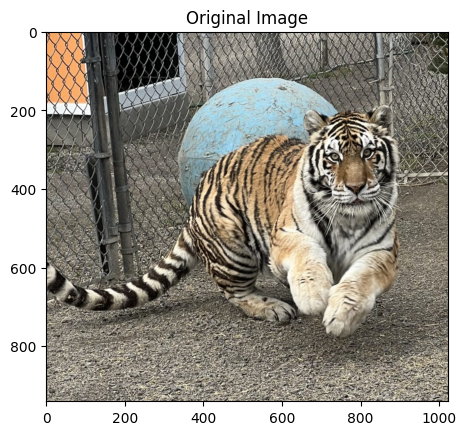

In [ ]:
import cv2
import matplotlib.pyplot as plt

image = cv2.imread("/content/drive/MyDrive/Colab Notebooks/Lab 6/image/1.jpg")
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.imshow(image)
plt.title("Original Image")
plt.show()

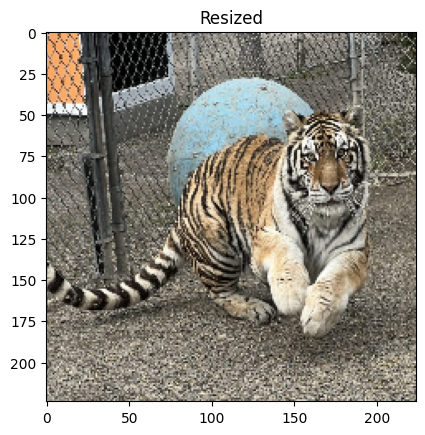

In [ ]:
# Resize
resized = cv2.resize(image,(224,224))

plt.imshow(resized)
plt.title("Resized")
plt.show()

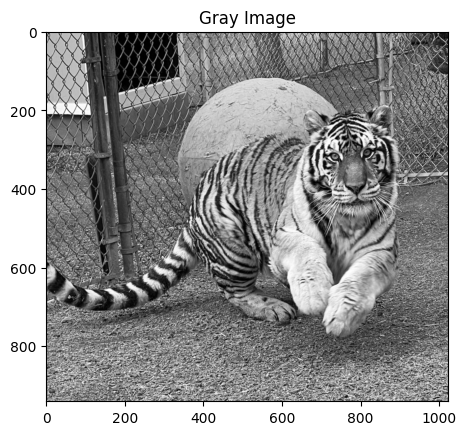

In [ ]:
# Grayscale
gray = cv2.cvtColor(image,cv2.COLOR_RGB2GRAY)

plt.imshow(gray,cmap='gray')
plt.title("Gray Image")
plt.show()

In [ ]:
#Normalization
normalized = gray/255.0

print(normalized.min())
print(normalized.max())

0.0
1.0


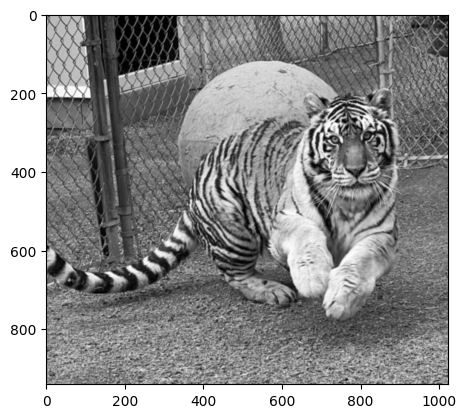

In [ ]:
#Noise Removal
blur = cv2.GaussianBlur(gray,(5,5),0)

plt.imshow(blur,cmap='gray')
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import cv2
import numpy as np
from matplotlib import pyplot as plt

In [ ]:
input_folder = "/content/drive/MyDrive/Colab Notebooks/Lab 6/image3"

In [ ]:
base_output = "/content/drive/MyDrive/Dataset"

folders = [
    "Resize",
    "Gray",
    "Gaussian",
    "Histogram",
    "Normalize",
    "Edge"
]

for folder in folders:
    os.makedirs(os.path.join(base_output, folder), exist_ok=True)

In [ ]:
image_files = os.listdir(input_folder)

print(image_files)

['Bird1.jpg', 'Bird2.jpg', 'Bird3.jpg', 'Bird4.jpg', 'Bird5.jpg', 'Bird6.avif', 'Bird6.jpg', 'Bird7.jpg', 'Bird8.jpg', 'Bird9.jpg', 'Bird10.jpg', 'Bird11.jpg']


In [ ]:
for file in image_files:

    path = os.path.join(input_folder,file)

    image = cv2.imread(path)

    if image is None:
        continue

In [ ]:
  # Resize

  resize = cv2.resize(image,(224,224))

  cv2.imwrite(
        os.path.join(base_output,"Resize",file),
        resize
    )


True

In [ ]:
  # Gray
gray = cv2.cvtColor(resize,cv2.COLOR_BGR2GRAY)

cv2.imwrite(
        os.path.join(base_output,"Gray",file),
        gray
    )

True

In [ ]:
   # Gaussian Blur
blur = cv2.GaussianBlur(gray,(5,5),0)

cv2.imwrite(
        os.path.join(base_output,"Gaussian",file),
        blur
    )

True

In [ ]:
    # Histogram Equalization

hist = cv2.equalizeHist(blur)

cv2.imwrite(
        os.path.join(base_output,"Histogram",file),
        hist
    )

True

In [ ]:
    # Normalize
norm = cv2.normalize(
        hist,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    )

cv2.imwrite(
        os.path.join(base_output,"Normalize",file),
        norm
    )

True

In [ ]:
    # Edge Detection

edge = cv2.Canny(norm,100,200)

cv2.imwrite(
        os.path.join(base_output,"Edge",file),
        edge
    )

print("Processing Finished")

Processing Finished


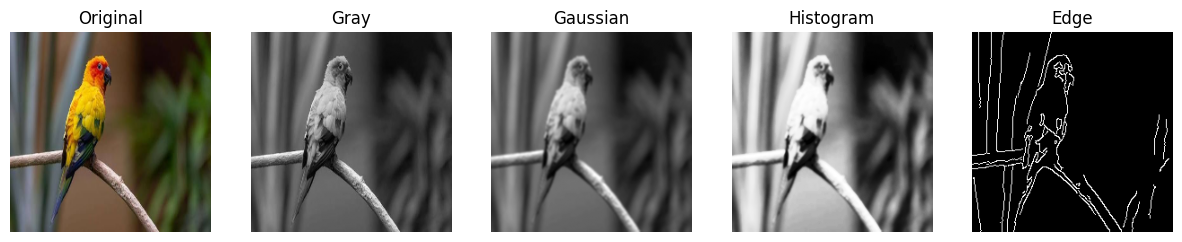

In [ ]:
sample = image_files[0]

img = cv2.imread(os.path.join(input_folder,sample))
img = cv2.resize(img,(224,224))

gray = cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(gray,(5,5),0)
hist = cv2.equalizeHist(blur)
edge = cv2.Canny(hist,100,200)

plt.figure(figsize=(15,5))

plt.subplot(1,5,1)
plt.imshow(cv2.cvtColor(img,cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.axis("off")

plt.subplot(1,5,2)
plt.imshow(gray,cmap="gray")
plt.title("Gray")
plt.axis("off")

plt.subplot(1,5,3)
plt.imshow(blur,cmap="gray")
plt.title("Gaussian")
plt.axis("off")

plt.subplot(1,5,4)
plt.imshow(hist,cmap="gray")
plt.title("Histogram")
plt.axis("off")

plt.subplot(1,5,5)
plt.imshow(edge,cmap="gray")
plt.title("Edge")
plt.axis("off")

plt.show()

## Task 4: Image Augmentation

In [ ]:
import os
import cv2
import random

# Input and Output Folder
input_folder = "/content/drive/MyDrive/Colab Notebooks/Lab 6/image3"
output_folder = "/content/drive/MyDrive/Colab Notebooks/Lab 6/image4"

os.makedirs(output_folder, exist_ok=True)

# Supported image extensions
extensions = ('.jpg', '.jpeg', '.png')

for filename in os.listdir(input_folder):

    if filename.lower().endswith(extensions):

        img_path = os.path.join(input_folder, filename)
        image = cv2.imread(img_path)

        # Original Image Save
        cv2.imwrite(os.path.join(output_folder, filename), image)

        name = os.path.splitext(filename)[0]

        # -------- Augmentation 1 : Horizontal Flip --------
        flip = cv2.flip(image, 1)
        cv2.imwrite(os.path.join(output_folder, f"{name}_flip.jpg"), flip)

        # -------- Augmentation 2 : Random Rotation --------
        angle = random.randint(-30, 30)

        h, w = image.shape[:2]
        center = (w//2, h//2)

        M = cv2.getRotationMatrix2D(center, angle, 1.0)
        rotated = cv2.warpAffine(image, M, (w, h))

        cv2.imwrite(os.path.join(output_folder, f"{name}_rotate.jpg"), rotated)

print("Augmentation Completed!")
print("Images are saved in:", output_folder)

Augmentation Completed!
Images are saved in: /content/drive/MyDrive/Colab Notebooks/Lab 6/image4
